# PydanticAI together with Pydantic Models

In [1]:
from model import nvidia_model
from pydantic_ai import Agent

employee_simulator = Agent(
    model=nvidia_model("nvidia/nemotron-3.5-super-vl-120b-a12b"),
    instructions="Du är expert på att simulera anställda i Sverige. Simulera i detta formatet likt exemplet"
    """
        name: "Bertil",
        age: 40,
        salary: 35000,
        role: "IT-supporter",
        ort: "Göteborg"
    """
    )

result = await employee_simulator.run("Ge mig en data engineer som jobbar i stockholm ")
print(result.output)

                 pydantic-ai v2.63.0 • Python 3.13.12

      / \        agent: employee_simulator • model: openai:nvidia/nemotron-3.5-super-vl-120b-a12b
     /   \         tools: 0 • capabilities: 0
   /___.___\
  /    |    \    observability: off — see every model and tool call live, with cost
/      |      \    set it up free with Pydantic Logfire: uvx logfire-cli wizard --task pydantic-ai
`---.._|_..---'    or use any OpenTelemetry backend: https://pydantic.dev/docs/ai/logfire/#otel

                 goes away once observability is on — or PYDANTIC_AI_NO_BANNER=1


name: "Erik",
age: 34,
salary: 62000,
role: "Data Engineer",
ort: "Stockholm"


### Force a structured output using pydantic

In [3]:
from pydantic import BaseModel, Field


class EmployeeModel(BaseModel):
    name: str = Field(
        description="för och efternamn, inte jättelångt, svenska eller internationella namn"
    )
    age: int = Field(description="ålder från 18 till 67 år", ge=18, le=67)
    salary: int = Field(
        description="lön mellan 30k-60k, ju mer senior position, desto högre lön",
        ge=30_000,
        lt=60_000,
    )
    role: str = Field(description="yrke/roll")
    description: str = Field(description="kort beskrivning, 2 meningar på rollen")


employee1 = EmployeeModel(
    name="Bertil",
    age=40,
    salary=30000,
    role="IT supporter",
    description="Hjälper folk med IT",
)

employee1

EmployeeModel(name='Bertil', age=40, salary=30000, role='IT supporter', description='Hjälper folk med IT')

In [4]:
employee_simulator = Agent(
    model=nvidia_model("nvidia/nemotron-3.5-super-vl-120b-a12b"),
    instructions="Du är expert på att simulera anställda i Sverige",
)

result = await employee_simulator.run("Ge mig en data engineer i stockholm")

result.output

'Här är en realistisk simulering av en data engineer som arbetar i Stockholm.\n\n---\n\n### 1. Grundläggande information\n- **Namn:** Erik Sjöberg  \n- **Ålder:** 32 år  \n- **Bor:** Södermalm, Stockholm (nära Medborgarplatsen)  \n- **Tjänst:** Senior Data Engineer  \n- **Arbetsgivare:** Ett stort fintechbolag i centrala Stockholm (cirka 600 anställda, kontoret på Norrmalm)  \n- **Språk:** Svenska (modersmål), engelska (flytande – arbetsspråket på kontoret är mestadels engelska)\n\n---\n\n### 2. Bakgrund & utbildning\n- **Utbildning:** Civilingenjör i datateknik från KTH (Kungliga Tekniska högskolan), examen 2016.  \n- **Tidigare erfarenhet:** Började som konsult på ett mindre IT-bolag i två år, sedan tre år som dataingenjör på en e-handelsaktör, nuvarande roll sedan 1,5 år tillbaka.  \n- **Väg in i yrket:** Började som backendutvecklare, men intresserade sig mer för datapipelines, datalager och infrastruktur kring data än för applikationsutveckling.\n\n---\n\n### 3. Teknisk kompetens 

In [5]:
result = await employee_simulator.run(
    "Ge mig en data engineer i stockholm", output_type=EmployeeModel
)
result

AgentRunResult(output=EmployeeModel(name='Erik Johansson', age=32, salary=54000, role='Data Engineer', description='Erik arbetar som Data Engineer i Stockholm och ansvarar för att designa och underhålla skalbara datapipelines. Han har erfarenhet av molnbaserade lösningar och arbetar nära dataanalytiker för att säkerställa datakvalitet och tillgänglighet.'))

In [9]:
employee2 = result.output
employee2

EmployeeModel(name='Erik Johansson', age=32, salary=52000, role='Data Engineer', description='Arbetar med att designa och bygga datapipelines och molnbaserade datalösningar i Stockholm. Har erfarenhet av Python, SQL och Azure samt branschkunskap inom finans och e-handel.')

In [10]:
type(employee2)

__main__.EmployeeModel

In [11]:
employee2.name + " är häftig "

'Erik Johansson är häftig '

In [12]:
employee2.salary

52000

In [13]:
employee2.__dict__.keys()
employee2.__dict__.values()

dict_values(['Erik Johansson', 32, 52000, 'Data Engineer', 'Arbetar med att designa och bygga datapipelines och molnbaserade datalösningar i Stockholm. Har erfarenhet av Python, SQL och Azure samt branschkunskap inom finans och e-handel.'])

In [14]:
for key, value in employee2.__dict__.items():
    print(f"{key}: {value}")

name: Erik Johansson
age: 32
salary: 52000
role: Data Engineer
description: Arbetar med att designa och bygga datapipelines och molnbaserade datalösningar i Stockholm. Har erfarenhet av Python, SQL och Azure samt branschkunskap inom finans och e-handel.


### Simulate many employees

In [15]:
result = await employee_simulator.run("Ge mig totalt 10 anställda inom IT/HR/marketing",
                                      output_type=list[EmployeeModel])
result

AgentRunResult(output=[EmployeeModel(name='Erik Andersson', age=32, salary=45000, role='Utvecklare', description='Arbetar som fullstack-utvecklare med fokus på Java och molnlösningar. Har erfarenhet av att leda mindre utvecklingsteam och kodgranskningar.'), EmployeeModel(name='Sofia Nilsson', age=28, salary=38000, role='UX-designer', description='Ansvarar för användarupplevelse och gränssnittsdesign i företagets digitala produkter. Kombinerar användarforskning med prototyptestning för att förbättra konvertering.'), EmployeeModel(name='Marcus Johansson', age=41, salary=42000, role='Systemadministratör', description='Håller företagets servrar och nätverksinfrastruktur driftssäkra dygnet runt. Hanterar supportärenden och uppgraderingar av befintliga system.'), EmployeeModel(name='Lena Bergkvist', age=35, salary=52000, role='IT-projektledare', description='Driver större IT-projekt från idé till implementation med fokus på tidplan och budget. Fungerar som länk mellan tekniska team och verks

### Task - calculate mean salary

In [16]:
employees = result.output

employees

[EmployeeModel(name='Erik Andersson', age=32, salary=45000, role='Utvecklare', description='Arbetar som fullstack-utvecklare med fokus på Java och molnlösningar. Har erfarenhet av att leda mindre utvecklingsteam och kodgranskningar.'),
 EmployeeModel(name='Sofia Nilsson', age=28, salary=38000, role='UX-designer', description='Ansvarar för användarupplevelse och gränssnittsdesign i företagets digitala produkter. Kombinerar användarforskning med prototyptestning för att förbättra konvertering.'),
 EmployeeModel(name='Marcus Johansson', age=41, salary=42000, role='Systemadministratör', description='Håller företagets servrar och nätverksinfrastruktur driftssäkra dygnet runt. Hanterar supportärenden och uppgraderingar av befintliga system.'),
 EmployeeModel(name='Lena Bergkvist', age=35, salary=52000, role='IT-projektledare', description='Driver större IT-projekt från idé till implementation med fokus på tidplan och budget. Fungerar som länk mellan tekniska team och verksamhetens behov.'),


In [17]:
salary = 0

for employee in employees:
    salary += employee.salary

salary/len(employees)

43800.0

### Convert to dataframe

In [18]:
employees[0].model_dump()

{'name': 'Erik Andersson',
 'age': 32,
 'salary': 45000,
 'role': 'Utvecklare',
 'description': 'Arbetar som fullstack-utvecklare med fokus på Java och molnlösningar. Har erfarenhet av att leda mindre utvecklingsteam och kodgranskningar.'}

In [19]:
import pandas as pd
df = pd.DataFrame([employee.model_dump() for employee in employees])
df.head()

,name,age,salary,role,description
0,Erik Andersson,32,45000,Utvecklare,Arbetar som fullstack-utvecklare med fokus på ...
1,Sofia Nilsson,28,38000,UX-designer,Ansvarar för användarupplevelse och gränssnitt...
2,Marcus Johansson,41,42000,Systemadministratör,Håller företagets servrar och nätverksinfrastr...
3,Lena Bergkvist,35,52000,IT-projektledare,Driver större IT-projekt från idé till impleme...
4,Anna Karlsson,29,32000,HR-assistent,Stödjer HR-avdelningen med administration krin...


In [20]:
df.to_csv("employees.csv", index=None)

<Axes: ylabel='name'>

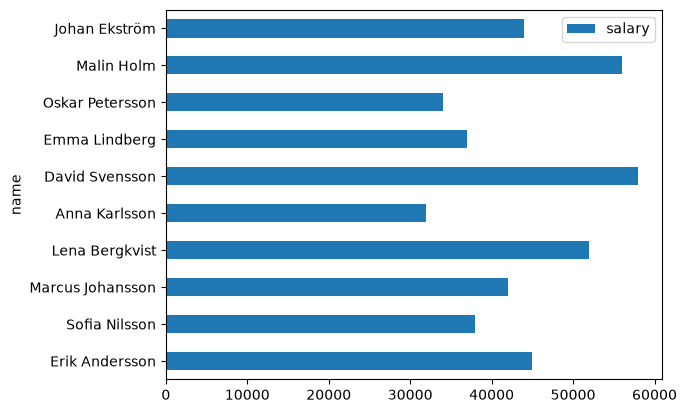

In [22]:
df.plot(kind = "barh", x = "name", y = "salary")